# Notebook 4 · Comparação e otimização de modelos

Comparamos seis algoritmos de classificação, com e sem seleção L1 (`C=0.1`), para prever `repeat_purchase_90d`. A preparação segue os NB_2/3 e a avaliação respeita a ordem temporal e uma margem de 90 dias. Os dois candidatos mais promissores são otimizados antes de fixar a receita para o NB_5.

As decisões usam apenas as divisões internas de desenvolvimento. `X_val`, já consultado no NB_3, é utilizado para diagnóstico adicional e não constitui uma avaliação independente. O teste Kaggle não participa na escolha.

O notebook é autónomo e deve ser executado na raiz ou em `notebooks/`, no ambiente `machine_learning`. As versões são registadas e os resultados são calculados em execução.

## 1. Preparação dos dados

Reproduzimos a preparação dos NB_2/3: correção das médias históricas inconsistentes quando sustentada pelos componentes; substituição de gastos de 365 dias inválidos e intervalos negativos por ausentes; exclusão das 65 linhas quase vazias; imputação, indicadores de ausência, one-hot e padronização.

Mantemos 34 variáveis de base. Identificadores, data absoluta, alvo e `random_noise` não entram nas features; a ficha de clientes permanece excluída. A data é conservada para avaliação temporal. O conjunto utilizável é separado em 5024 compras de ajuste, 147 na margem temporal e 1298 para verificação adicional. As transformações aprendidas são ajustadas dentro de cada treino.

In [35]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data" / "Raw" / "train.csv").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "Raw"
assert (DATA / "train.csv").exists(), "Executa a partir da raiz ou de notebooks/."

train_raw = pd.read_csv(DATA / "train.csv")
test_raw = pd.read_csv(DATA / "test.csv")
clientes = pd.read_csv(DATA / "clientes.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print({name: df.shape for name, df in {
    "train": train_raw, "test": test_raw, "clientes": clientes, "sample": sample
}.items()})

{'train': (6534, 39), 'test': (986, 38), 'clientes': (1143, 13), 'sample': (986, 2)}


In [36]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data" / "Raw" / "train.csv").exists():
    ROOT = ROOT.parent
DATA = ROOT / "data" / "Raw"
assert (DATA / "train.csv").exists(), "Executa a partir da raiz ou de notebooks/."

train_raw = pd.read_csv(DATA / "train.csv")
test_raw = pd.read_csv(DATA / "test.csv")
clientes = pd.read_csv(DATA / "clientes.csv")
sample = pd.read_csv(DATA / "sample_submission.csv")
print({name: df.shape for name, df in {
    "train": train_raw, "test": test_raw, "clientes": clientes, "sample": sample
}.items()})

{'train': (6534, 39), 'test': (986, 38), 'clientes': (1143, 13), 'sample': (986, 2)}


In [37]:
TARGET = "repeat_purchase_90d"
assert TARGET in train_raw and TARGET not in test_raw
assert set(train_raw.columns) - set(test_raw.columns) == {TARGET}
assert set(test_raw.columns) - set(train_raw.columns) == set()
assert train_raw["ID"].is_unique and test_raw["ID"].is_unique
assert clientes["customer_id"].is_unique
assert sample["ID"].tolist() == test_raw["ID"].tolist()
assert sample.columns.tolist() == ["ID", TARGET]
assert train_raw[TARGET].isin([0, 1]).all()
print("Estrutura, IDs e ordem da submissão: OK")

Estrutura, IDs e ordem da submissão: OK


In [38]:
def clean_fixed(frame):
    out = frame.copy()
    out["purchase_date"] = pd.to_datetime(out["purchase_date"], errors="coerce")

    col = "prior_mean_purchase_value"
    invalid_mean = out[col].lt(0) | out[col].ge(1e8)
    valid_parts = out["prior_purchase_count"].gt(0) & out["prior_total_spend"].ge(0)
    reconstructed = out["prior_total_spend"] / out["prior_purchase_count"].replace(0, np.nan)
    out.loc[invalid_mean & valid_parts, col] = reconstructed[invalid_mean & valid_parts]
    out.loc[invalid_mean & ~valid_parts, col] = np.nan

    outside_bounds = (
        out[col].lt(out["prior_min_purchase_value"] - 0.05) |
        out[col].gt(out["prior_max_purchase_value"] + 0.05)
    )
    reconstructed_in_bounds = (
        reconstructed.ge(out["prior_min_purchase_value"] - 0.05) &
        reconstructed.le(out["prior_max_purchase_value"] + 0.05)
    )
    repair_bounds = outside_bounds & reconstructed_in_bounds & valid_parts
    out.loc[repair_bounds, col] = reconstructed[repair_bounds]

    identity_disagrees = (out[col] - reconstructed).abs().gt(
        np.maximum(0.05, 0.01 * reconstructed.abs())
    )
    repair_identity = identity_disagrees & reconstructed_in_bounds & valid_parts
    out.loc[repair_identity, col] = reconstructed[repair_identity]

    invalid_spend = (
        out["spend_365d"].lt(0) |
        out["spend_365d"].ge(1e8) |
        out["spend_365d"].gt(out["prior_total_spend"] + 0.05)
    )
    out["spend_365d"] = out["spend_365d"].mask(invalid_spend)

    for gap in ("days_since_previous_purchase", "prior_mean_gap_days"):
        out[gap] = out[gap].mask(out[gap].lt(0))
    return out

train_clean = clean_fixed(train_raw)
test_clean = clean_fixed(test_raw)
for name, before, after in (("train", train_raw, train_clean), ("test", test_raw, test_clean)):
    changed = {c: int((before[c].notna() & after[c].isna()).sum())
               for c in ("spend_365d", "days_since_previous_purchase", "prior_mean_gap_days")}
    repaired = int((before["prior_mean_purchase_value"].notna() &
                    after["prior_mean_purchase_value"].notna() &
                    (before["prior_mean_purchase_value"] -
                     after["prior_mean_purchase_value"]).abs().gt(0.05)).sum())
    print(name, "médias reconstruídas:", repaired, "| valores tornados em falta:", changed)

train médias reconstruídas: 78 | valores tornados em falta: {'spend_365d': 69, 'days_since_previous_purchase': 16, 'prior_mean_gap_days': 16}
test médias reconstruídas: 11 | valores tornados em falta: {'spend_365d': 11, 'days_since_previous_purchase': 2, 'prior_mean_gap_days': 2}


In [39]:
purchase_totals = ["Total a Pagar", "Total Bruto", "Total Liquido", "Total Imp_", "Custo"]
no_purchase_info = train_clean[purchase_totals].isna().all(axis=1)
usable = ~no_purchase_info & train_clean["purchase_date"].notna() & train_clean[TARGET].notna()
print("Linhas excluídas do treino:", int((~usable).sum()))
print("Linhas de treino utilizáveis:", int(usable.sum()))
assert len(test_clean) == len(sample)
assert test_clean["purchase_date"].notna().all()

Linhas excluídas do treino: 65
Linhas de treino utilizáveis: 6469


In [40]:
CLIENT_COLUMNS = ["customer_id", "customer_since_year", "country_or_region"]

def make_features(clean_frame, include_clientes=False):
    out = clean_frame.copy()
    if include_clientes:
        out = out.merge(clientes[CLIENT_COLUMNS], on="customer_id",
                        how="left", validate="m:1", sort=False)
        assert len(out) == len(clean_frame)
    X = out.drop(columns=["ID", "customer_id", "purchase_date", TARGET, "random_noise"],
                 errors="ignore")
    text_cols = X.select_dtypes(include=["str", "object", "category"]).columns
    for col in text_cols:
        X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
    return X

X_all = make_features(train_clean)
X_test = make_features(test_clean)
X = X_all.loc[usable].copy()
y = train_clean.loc[usable, TARGET].astype(int)
dates = train_clean.loc[usable, "purchase_date"]
assert X.columns.tolist() == X_test.columns.tolist()
assert len(X_test) == len(test_raw)
print("Variáveis de base:", X.shape[1], "| numéricas:",
      X.select_dtypes(include="number").shape[1],
      "| categóricas:", X.select_dtypes(exclude="number").shape[1])

Variáveis de base: 34 | numéricas: 28 | categóricas: 6


In [41]:
boundary = dates.sort_values().iloc[int(0.8 * len(dates))]
purge_start = boundary - pd.Timedelta(days=90)
fit_rows = dates < purge_start
validation_rows = dates >= boundary

X_fit, y_fit = X.loc[fit_rows], y.loc[fit_rows]
X_val, y_val = X.loc[validation_rows], y.loc[validation_rows]
assert dates.loc[fit_rows].max() < purge_start
assert dates.loc[validation_rows].min() >= boundary
assert not X_fit.index.intersection(X_val.index).size

print("Início da validação:", boundary.date())
print("Última data do treino:", dates.loc[fit_rows].max().date())
print("Linhas para ajuste:", len(X_fit), "| validação:", len(X_val),
      "| margem:", int((~fit_rows & ~validation_rows).sum()))

Início da validação: 2023-06-17
Última data do treino: 2023-03-18
Linhas para ajuste: 5024 | validação: 1298 | margem: 147


In [42]:
def make_preprocessor(X_reference, scale_numeric=True):
    numeric_cols = X_reference.select_dtypes(include="number").columns.tolist()
    category_cols = X_reference.select_dtypes(exclude="number").columns.tolist()
    numeric_steps = [
        ("impute", SimpleImputer(strategy="median", add_indicator=True,
                                 keep_empty_features=True))
    ]
    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))
    numeric_pipe = Pipeline(numeric_steps)
    category_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="__missing__",
                                 keep_empty_features=True)),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                 min_frequency=20))
    ])
    return ColumnTransformer([
        ("numeric", numeric_pipe, numeric_cols),
        ("category", category_pipe, category_cols)
    ])

## 2. Estratégia de avaliação

A métrica principal é a **ROC-AUC**, em continuidade com o NB_3. Balanced accuracy, precisão, recall e F1 complementam a avaliação com limiar 0.5; log loss e Brier descrevem a qualidade das probabilidades. Não assumimos custos comerciais nem otimizamos o limiar. A métrica oficial do Kaggle deve ser confirmada antes da submissão.

Reutilizamos três divisões cronológicas dentro de `X_fit`, com margem de 90 dias. Os mesmos períodos são usados por todos os candidatos. Clientes podem repetir-se entre treino e avaliação, refletindo o objetivo de prever compras futuras de clientes conhecidos e novos.

Os períodos internos já foram utilizados no NB_3 e são reutilizados na procura de parâmetros. Assim, as médias são resultados de desenvolvimento sujeitos a viés de escolha; este procedimento não é uma validação temporal aninhada independente. A tabela seguinte apresenta a composição de cada divisão.

In [43]:
import platform
import time
import warnings
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectFromModel, VarianceThreshold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (roc_auc_score, balanced_accuracy_score, accuracy_score,
                             precision_score, recall_score, f1_score, log_loss,
                             brier_score_loss, confusion_matrix,
                             ConfusionMatrixDisplay, RocCurveDisplay)

RANDOM_STATE = 42
THRESHOLD = 0.5
print({"Python": platform.python_version(), "scikit-learn": sklearn.__version__,
       "pandas": pd.__version__, "numpy": np.__version__,
       "matplotlib": matplotlib.__version__})

date_fit = dates.loc[X_fit.index]
ordered = date_fit.sort_values()
starts = [ordered.iloc[int(q * len(ordered))] for q in (0.50, 0.65, 0.80)]
ends = starts[1:] + [date_fit.max() + pd.Timedelta(days=1)]
inner_folds, fold_description = [], []
for number, (start, end) in enumerate(zip(starts, ends), start=1):
    train_index = date_fit.index[date_fit < start - pd.Timedelta(days=90)]
    check_index = date_fit.index[(date_fit >= start) & (date_fit < end)]
    assert len(train_index) and len(check_index)
    assert not train_index.intersection(check_index).size
    assert date_fit.loc[train_index].max() + pd.Timedelta(days=90) < start
    assert y_fit.loc[train_index].nunique() == y_fit.loc[check_index].nunique() == 2
    inner_folds.append((train_index, check_index))
    fold_description.append({
        "divisão": number, "linhas treino": len(train_index),
        "linhas avaliação": len(check_index),
        "fim treino": date_fit.loc[train_index].max().date(),
        "início avaliação": date_fit.loc[check_index].min().date(),
        "fim avaliação": date_fit.loc[check_index].max().date(),
        "taxa alvo treino": y_fit.loc[train_index].mean(),
        "taxa alvo avaliação": y_fit.loc[check_index].mean(),
    })
display(pd.DataFrame(fold_description).set_index("divisão"))

{'Python': '3.13.5', 'scikit-learn': '1.9.0', 'pandas': '3.0.3', 'numpy': '2.4.6', 'matplotlib': '3.11.0'}


,linhas treino,linhas avaliação,fim treino,início avaliação,fim avaliação,taxa alvo treino,taxa alvo avaliação
divisão,,,,,,,
1,2347,760,2019-05-25,2019-08-24,2020-10-14,0.555177,0.551316
2,3132,755,2020-07-17,2020-10-16,2021-10-12,0.552363,0.600000
3,3831,1005,2021-07-16,2021-10-15,2023-03-18,0.561211,0.494527


## 3. Algoritmos e seleção de variáveis

Comparamos regressão logística, árvore de decisão, Random Forest, KNN, SVM RBF e Gaussian Naive Bayes. Cada família é avaliada sem seleção e com L1 (`C=0.1`), cuja seleção é reaprendida em cada treino. A referência sem seleção permite verificar se a redução proposta no NB_3 também beneficia outros algoritmos.

As configurações iniciais estão explicitadas no código. Mantemos a preparação comum: imputação por mediana com indicadores, categoria para ausentes, agrupamento de categorias com menos de 20 ocorrências, one-hot, padronização e remoção de constantes. As matrizes são densas para compatibilidade com GaussianNB. Não acrescentamos logaritmos, atributos de clientes ou reequilíbrio das classes nesta comparação.

O SVC estima probabilidades internamente; essa etapa não constitui avaliação temporal. No scikit-learn 1.9.0 do projeto, `probability=True` funciona com aviso de descontinuação. Os avisos são registados e a compatibilidade deve ser revista numa migração de versão.

In [44]:
MODELS = {
    "Logística": LogisticRegression(solver="liblinear", C=1, max_iter=3000,
                                    random_state=RANDOM_STATE),
    "Árvore": DecisionTreeClassifier(max_depth=6, min_samples_leaf=10,
                                     random_state=RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                             n_jobs=1, random_state=RANDOM_STATE),
    "KNN": KNeighborsClassifier(n_neighbors=31, weights="distance", n_jobs=1),
    "SVM RBF": SVC(C=1, gamma="scale", probability=True, cache_size=256,
                   random_state=RANDOM_STATE),
    "GaussianNB": GaussianNB(),
}
SELECTIONS = ("Todas", "L1 C=0.1")

def build_model_pipeline(model_name, selection, model_params=None):
    preprocessor = make_preprocessor(X_fit, scale_numeric=True)
    preprocessor.set_params(sparse_threshold=0)
    selector = "passthrough"
    if selection == "L1 C=0.1":
        selector = SelectFromModel(
            LogisticRegression(solver="liblinear", l1_ratio=1, C=0.1,
                               max_iter=3000, random_state=RANDOM_STATE),
            threshold=1e-8,
        )
    else:
        assert selection == "Todas"
    model = clone(MODELS[model_name])
    if model_params:
        model.set_params(**model_params)
    return Pipeline([
        ("preprocess", preprocessor), ("variance", VarianceThreshold()),
        ("select", selector), ("model", model),
    ])

def selected_feature_names(pipeline):
    names = pipeline.named_steps["preprocess"].get_feature_names_out()
    names = names[pipeline.named_steps["variance"].get_support()]
    selector = pipeline.named_steps["select"]
    if not isinstance(selector, str):
        names = names[selector.get_support()]
    return list(names)

def score_predictions(actual, probabilities):
    assert len(actual) == len(probabilities)
    assert np.isfinite(probabilities).all()
    assert ((probabilities >= 0) & (probabilities <= 1)).all()
    predicted = (probabilities >= THRESHOLD).astype(int)
    return {
        "ROC-AUC": roc_auc_score(actual, probabilities),
        "balanced accuracy": balanced_accuracy_score(actual, predicted),
        "accuracy": accuracy_score(actual, predicted),
        "precisão": precision_score(actual, predicted, zero_division=0),
        "recall": recall_score(actual, predicted, zero_division=0),
        "F1": f1_score(actual, predicted, zero_division=0),
        "log loss": log_loss(actual, probabilities, labels=[0, 1]),
        "Brier": brier_score_loss(actual, probabilities),
    }

## 4. Comparação inicial

O baseline `DummyClassifier` usa a taxa do alvo no treino como probabilidade constante. A sua AUC é 0.5; não corresponde necessariamente ao baseline disponibilizado no Kaggle.

As 12 combinações de algoritmo e seleção são avaliadas nas mesmas três divisões, totalizando 36 ajustes. Em cada um, o pipeline completo é aprendido apenas com o treino. Registamos métricas, colunas, previsões, tempos e avisos para auditoria.

In [45]:
dummy_records = []
for number, (train_index, check_index) in enumerate(inner_folds, start=1):
    dummy = DummyClassifier(strategy="prior")
    dummy.fit(np.zeros((len(train_index), 1)), y_fit.loc[train_index])
    probabilities = dummy.predict_proba(np.zeros((len(check_index), 1)))[:, 1]
    dummy_records.append({"divisão": number,
                          **score_predictions(y_fit.loc[check_index], probabilities)})
dummy_results = pd.DataFrame(dummy_records)
display(dummy_results.round(4))

evaluation_records, prediction_records, feature_records, warning_records = [], [], [], []
candidate_specs = {}

def evaluate_candidate(candidate_id, model_name, selection, params, stage):
    candidate_specs[candidate_id] = {
        "modelo": model_name, "seleção": selection, "parâmetros": dict(params),
        "fase": stage,
    }
    rows = []
    for number, (train_index, check_index) in enumerate(inner_folds, start=1):
        pipeline = build_model_pipeline(model_name, selection, params)
        start_time = time.perf_counter()
        with warnings.catch_warnings(record=True) as captured:
            warnings.simplefilter("always")
            pipeline.fit(X_fit.loc[train_index], y_fit.loc[train_index])
            probabilities = pipeline.predict_proba(X_fit.loc[check_index])[:, 1]
        elapsed = time.perf_counter() - start_time
        for warning in captured:
            warning_records.append({"candidato": candidate_id, "divisão": number,
                                    "tipo": warning.category.__name__,
                                    "mensagem": str(warning.message)})
        names = selected_feature_names(pipeline)
        row = {"candidato": candidate_id, "modelo": model_name, "seleção": selection,
               "fase": stage, "divisão": number, "colunas": len(names),
               "segundos": elapsed,
               **score_predictions(y_fit.loc[check_index], probabilities)}
        rows.append(row)
        for row_index, probability in zip(check_index, probabilities):
            prediction_records.append({
                "candidato": candidate_id, "divisão": number,
                "ID": int(train_clean.loc[row_index, "ID"]),
                "alvo": int(y_fit.loc[row_index]), "probabilidade": float(probability),
            })
        feature_records.append({"candidato": candidate_id, "divisão": number,
                                "colunas": names})
    evaluation_records.extend(rows)
    print(f"{candidate_id}: AUC média={np.mean([r['ROC-AUC'] for r in rows]):.4f}",
          f"| colunas médias={np.mean([r['colunas'] for r in rows]):.1f}", flush=True)

for model_name in MODELS:
    for selection in SELECTIONS:
        evaluate_candidate(f"Base | {model_name} | {selection}", model_name,
                           selection, {}, "base")

def summarise(records):
    table = pd.DataFrame(records).groupby(
        ["candidato", "modelo", "seleção", "fase"], sort=False
    ).agg(media_auc=("ROC-AUC", "mean"), desvio_auc=("ROC-AUC", "std"),
          minimo_auc=("ROC-AUC", "min"), maximo_auc=("ROC-AUC", "max"),
          media_balanced_accuracy=("balanced accuracy", "mean"),
          media_colunas=("colunas", "mean"), media_segundos=("segundos", "mean"))
    return table.reset_index().sort_values(
        ["media_auc", "media_colunas", "candidato"], ascending=[False, True, True]
    ).reset_index(drop=True)

benchmark = summarise(evaluation_records)
display(benchmark.round(4))
print("Avisos capturados:", len(warning_records))
if warning_records:
    display(pd.DataFrame(warning_records).drop_duplicates(["tipo", "mensagem"]))

,divisão,ROC-AUC,balanced accuracy,accuracy,precisão,recall,F1,log loss,Brier
0,1,0.5,0.5,0.5513,0.5513,1.0,0.7108,0.6879,0.2474
1,2,0.5,0.5,0.6000,0.6000,1.0,0.7500,0.6776,0.2423
2,3,0.5,0.5,0.4945,0.4945,1.0,0.6618,0.7020,0.2544


Base | Logística | Todas: AUC média=0.7742 | colunas médias=79.7
Base | Logística | L1 C=0.1: AUC média=0.7750 | colunas médias=27.3
Base | Árvore | Todas: AUC média=0.7307 | colunas médias=79.7
Base | Árvore | L1 C=0.1: AUC média=0.7339 | colunas médias=27.3
Base | Random forest | Todas: AUC média=0.7763 | colunas médias=79.7
Base | Random forest | L1 C=0.1: AUC média=0.7738 | colunas médias=27.3
Base | KNN | Todas: AUC média=0.7578 | colunas médias=79.7
Base | KNN | L1 C=0.1: AUC média=0.7572 | colunas médias=27.3
Base | SVM RBF | Todas: AUC média=0.7606 | colunas médias=79.7
Base | SVM RBF | L1 C=0.1: AUC média=0.7591 | colunas médias=27.3
Base | GaussianNB | Todas: AUC média=0.7265 | colunas médias=79.7
Base | GaussianNB | L1 C=0.1: AUC média=0.7639 | colunas médias=27.3


,candidato,modelo,seleção,fase,media_auc,desvio_auc,minimo_auc,maximo_auc,media_balanced_accuracy,media_colunas,media_segundos
0,Base | Random forest | Todas,Random forest,Todas,base,0.7763,0.0059,0.7714,0.7829,0.7022,79.6667,1.1857
1,Base | Logística | L1 C=0.1,Logística,L1 C=0.1,base,0.7750,0.0158,0.7580,0.7892,0.7169,27.3333,0.1795
2,Base | Logística | Todas,Logística,Todas,base,0.7742,0.0158,0.7644,0.7925,0.7041,79.6667,0.1290
3,Base | Random forest | L1 C=0.1,Random forest,L1 C=0.1,base,0.7738,0.0164,0.7553,0.7866,0.7036,27.3333,1.0765
4,Base | GaussianNB | L1 C=0.1,GaussianNB,L1 C=0.1,base,0.7639,0.0135,0.7505,0.7775,0.7174,27.3333,0.1186
5,Base | SVM RBF | Todas,SVM RBF,Todas,base,0.7606,0.0071,0.7526,0.7663,0.7000,79.6667,2.2358
6,Base | SVM RBF | L1 C=0.1,SVM RBF,L1 C=0.1,base,0.7591,0.0115,0.7486,0.7714,0.6964,27.3333,1.7090
7,Base | KNN | Todas,KNN,Todas,base,0.7578,0.0041,0.7535,0.7618,0.6899,79.6667,0.0750
8,Base | KNN | L1 C=0.1,KNN,L1 C=0.1,base,0.7572,0.0083,0.7519,0.7668,0.6922,27.3333,0.1278
9,Base | Árvore | L1 C=0.1,Árvore,L1 C=0.1,base,0.7339,0.0168,0.7177,0.7512,0.6889,27.3333,0.1400


Avisos capturados: 6


,candidato,divisão,tipo,mensagem
0,Base | SVM RBF | Todas,1,FutureWarning,The `probability` parameter was deprecated in ...


### Síntese e efeito da seleção

As médias atribuem o mesmo peso às três divisões; o desvio-padrão descreve variação entre períodos, sem constituir intervalo de confiança. A tabela emparelha as versões de cada algoritmo: uma diferença positiva favorece L1. O gráfico apresenta médias e resultados individuais, permitindo distinguir desempenho médio e estabilidade temporal.
Com base no gráfico podemos concluir que a Random Forest com "Todas" foi a melhor configuração inicial pela ROC-AUC. Contudo, a vantagem é pequena, já que esta não ganhou em todas as divisões (divisão 3 a logistica teve 0.7925)

seleção,L1 C=0.1,Todas,diferença L1 - Todas
modelo,,,
GaussianNB,0.7639,0.7265,0.0374
Árvore,0.7339,0.7307,0.0032
Logística,0.7750,0.7742,0.0008
KNN,0.7572,0.7578,-0.0006
SVM RBF,0.7591,0.7606,-0.0014
Random forest,0.7738,0.7763,-0.0025


divisão,1,2,3
candidato,,,
Base | GaussianNB | L1 C=0.1,0.7505,0.7775,0.7638
Base | GaussianNB | Todas,0.7477,0.7139,0.7179
Base | KNN | L1 C=0.1,0.7519,0.7530,0.7668
Base | KNN | Todas,0.7618,0.7535,0.7582
Base | Logística | L1 C=0.1,0.7580,0.7777,0.7892
Base | Logística | Todas,0.7658,0.7644,0.7925
Base | Random forest | L1 C=0.1,0.7553,0.7794,0.7866
Base | Random forest | Todas,0.7714,0.7747,0.7829
Base | SVM RBF | L1 C=0.1,0.7486,0.7574,0.7714


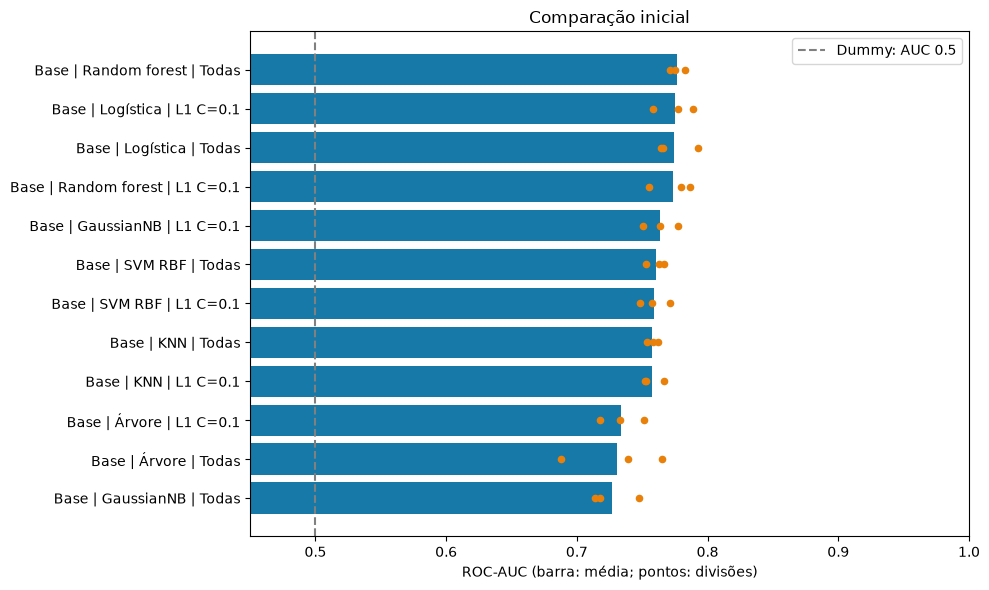

In [46]:
selection_effect = benchmark.pivot(index="modelo", columns="seleção", values="media_auc")
selection_effect["diferença L1 - Todas"] = (
    selection_effect["L1 C=0.1"] - selection_effect["Todas"]
)
display(selection_effect.sort_values("diferença L1 - Todas", ascending=False).round(4))
base_fold_results = pd.DataFrame(evaluation_records)
display(base_fold_results.pivot(index="candidato", columns="divisão", values="ROC-AUC").round(4))

fig, ax = plt.subplots(figsize=(10, 6))
ordered_benchmark = benchmark.sort_values("media_auc")
ax.barh(ordered_benchmark["candidato"], ordered_benchmark["media_auc"], color="#1779A8")
for position, candidate_id in enumerate(ordered_benchmark["candidato"]):
    values = base_fold_results.loc[base_fold_results["candidato"].eq(candidate_id), "ROC-AUC"]
    ax.scatter(values, [position] * len(values), color="#E8800A", s=20, zorder=3)
ax.axvline(0.5, linestyle="--", color="grey", label="Dummy: AUC 0.5")
ax.set(xlabel="ROC-AUC (barra: média; pontos: divisões)", title="Comparação inicial")
ax.set_xlim(0.45, 1)
ax.legend()
fig.tight_layout()
plt.show()

## 5. Otimização dos candidatos

Selecionamos as duas famílias com maior AUC média inicial e conservamos a melhor opção de seleção de cada uma. Avaliamos as grelhas seguintes nas mesmas divisões, reaprendendo a pipeline completa.

Esta procura é limitada: não cobre todas as combinações possíveis nem otimiza conjuntamente todas as opções de seleção. Reutilizar os períodos para otimizar pode tornar a melhor média otimista; `X_val` não intervém nesta escolha.

C menor --> penalização mais forte

C maior --> penalização mais fraca

max_depth --> profundidade máxima de cada árvore, None não impõe esse limite.

min_samples_leaf --> número minímo de compras que podem ficar numa folha, isto é, num grupo final de uma árvore.

A melhor foi Random Forest, todas as colunas, profundidade máxima 12 e mínimo 5 compras por folha



In [47]:
PARAMETER_GRIDS = {
    "Logística": {"C": [0.1, 1.0, 10.0]},
    "Árvore": {"max_depth": [3, 6, 10], "min_samples_leaf": [5, 20]},
    "Random forest": {"max_depth": [None, 12], "min_samples_leaf": [1, 5]},
}
shortlist = benchmark.drop_duplicates("modelo").head(2)
for _, row in shortlist.iterrows():
    model_name, selection = row["modelo"], row["seleção"]
    for number, params in enumerate(ParameterGrid(PARAMETER_GRIDS[model_name]), start=1):
        evaluate_candidate(f"Grelha | {model_name} | {selection} | {number}",
                           model_name, selection, params, "otimização")

all_comparison = summarise(evaluation_records)
display(all_comparison.head(15).round(4))
print("Avisos em todos os ajustes:", len(warning_records))
if warning_records:
    display(pd.DataFrame(warning_records).drop_duplicates(["tipo", "mensagem"]))

Grelha | Random forest | Todas | 1: AUC média=0.7635 | colunas médias=79.7
Grelha | Random forest | Todas | 2: AUC média=0.7794 | colunas médias=79.7
Grelha | Random forest | Todas | 3: AUC média=0.7738 | colunas médias=79.7
Grelha | Random forest | Todas | 4: AUC média=0.7803 | colunas médias=79.7
Grelha | Logística | L1 C=0.1 | 1: AUC média=0.7766 | colunas médias=27.3
Grelha | Logística | L1 C=0.1 | 2: AUC média=0.7750 | colunas médias=27.3
Grelha | Logística | L1 C=0.1 | 3: AUC média=0.7743 | colunas médias=27.3


,candidato,modelo,seleção,fase,media_auc,desvio_auc,minimo_auc,maximo_auc,media_balanced_accuracy,media_colunas,media_segundos
0,Grelha | Random forest | Todas | 4,Random forest,Todas,otimização,0.7803,0.0075,0.7722,0.7869,0.6987,79.6667,0.9077
1,Grelha | Random forest | Todas | 2,Random forest,Todas,otimização,0.7794,0.0072,0.7716,0.7856,0.6976,79.6667,0.9574
2,Grelha | Logística | L1 C=0.1 | 1,Logística,L1 C=0.1,otimização,0.7766,0.0172,0.7582,0.7922,0.7174,27.3333,0.1107
3,Base | Random forest | Todas,Random forest,Todas,base,0.7763,0.0059,0.7714,0.7829,0.7022,79.6667,1.1857
4,Base | Logística | L1 C=0.1,Logística,L1 C=0.1,base,0.7750,0.0158,0.7580,0.7892,0.7169,27.3333,0.1795
5,Grelha | Logística | L1 C=0.1 | 2,Logística,L1 C=0.1,otimização,0.7750,0.0158,0.7580,0.7892,0.7169,27.3333,0.1126
6,Grelha | Logística | L1 C=0.1 | 3,Logística,L1 C=0.1,otimização,0.7743,0.0154,0.7579,0.7885,0.7178,27.3333,0.1138
7,Base | Logística | Todas,Logística,Todas,base,0.7742,0.0158,0.7644,0.7925,0.7041,79.6667,0.1290
8,Grelha | Random forest | Todas | 3,Random forest,Todas,otimização,0.7738,0.0082,0.7656,0.7821,0.7007,79.6667,1.0309
9,Base | Random forest | L1 C=0.1,Random forest,L1 C=0.1,base,0.7738,0.0164,0.7553,0.7866,0.7036,27.3333,1.0765


Avisos em todos os ajustes: 6


,candidato,divisão,tipo,mensagem
0,Base | SVM RBF | Todas,1,FutureWarning,The `probability` parameter was deprecated in ...


## 6. Escolha da receita

Escolhemos a maior ROC-AUC média interna entre configurações iniciais e otimizadas. 

Reportamos a dispersão e a diferença face à melhor configuração inicial da mesma família.


In [48]:
chosen_row = all_comparison.iloc[0]
chosen_id = chosen_row["candidato"]
chosen_spec = candidate_specs[chosen_id]
chosen_model_name = chosen_spec["modelo"]
base_same_family = benchmark.loc[benchmark["modelo"].eq(chosen_model_name)].iloc[0]
internal_gain = chosen_row["media_auc"] - base_same_family["media_auc"]
print("Parâmetros adicionais:", chosen_spec["parâmetros"])
print(f"AUC média interna: {chosen_row['media_auc']:.4f}")
print(f"Variação por período (desvio): {chosen_row['desvio_auc']:.4f}")
print(f"Diferença para a melhor base da mesma família: {internal_gain:+.4f}")
display(pd.DataFrame(evaluation_records).loc[
    lambda frame: frame["candidato"].eq(chosen_id),
    ["divisão", "ROC-AUC", "balanced accuracy", "precisão", "recall", "colunas", "segundos"]
].round(4))

Parâmetros adicionais: {'max_depth': 12, 'min_samples_leaf': 5}
AUC média interna: 0.7803
Variação por período (desvio): 0.0075
Diferença para a melhor base da mesma família: +0.0040


,divisão,ROC-AUC,balanced accuracy,precisão,recall,colunas,segundos
45,1,0.7722,0.6839,0.7136,0.7255,76,0.6863
46,2,0.7819,0.7114,0.7807,0.7307,79,0.8813
47,3,0.7869,0.7010,0.6808,0.7425,84,1.1556


## 7. Verificação temporal adicional

Ajustamos a receita escolhida em todo `X_fit` e avaliamos em `X_val`, comparando com o Dummy. Este resultado não é utilizado para alterar a escolha.

Como `X_val` foi consultado no NB_3, esta avaliação tem finalidade diagnóstica e não é independente de todo o desenvolvimento. Uma avaliação mais rigorosa da estratégia de escolha exigiria validação temporal aninhada ou dados futuros não consultados. O ajuste final com todas as compras utilizáveis fica para o NB_5.

In [49]:
chosen_pipeline = build_model_pipeline(chosen_model_name, chosen_spec["seleção"],
                                        chosen_spec["parâmetros"])
with warnings.catch_warnings(record=True) as final_warnings:
    warnings.simplefilter("always")
    chosen_pipeline.fit(X_fit, y_fit)
    val_probabilities = chosen_pipeline.predict_proba(X_val)[:, 1]
for warning in final_warnings:
    print(warning.category.__name__, str(warning.message))
val_predictions = (val_probabilities >= THRESHOLD).astype(int)
dummy = DummyClassifier(strategy="prior").fit(np.zeros((len(y_fit), 1)), y_fit)
dummy_probabilities = dummy.predict_proba(np.zeros((len(y_val), 1)))[:, 1]
holdout = pd.DataFrame([
    {"receita": "Escolhida", **score_predictions(y_val, val_probabilities)},
    {"receita": "Dummy", **score_predictions(y_val, dummy_probabilities)},
]).set_index("receita")
display(holdout.round(4))
final_names = selected_feature_names(chosen_pipeline)
print("Colunas depois da preparação e seleção:", len(final_names))
print("Compras avaliadas:", len(y_val), "| taxa real de recompra:", round(y_val.mean(), 4))
assert len(val_probabilities) == len(X_val)
assert len(final_names) > 0

,ROC-AUC,balanced accuracy,accuracy,precisão,recall,F1,log loss,Brier
receita,,,,,,,,
Escolhida,0.8016,0.7204,0.7296,0.7820,0.765,0.7734,0.5372,0.1808
Dummy,0.5000,0.5000,0.6032,0.6032,1.000,0.7525,0.6775,0.2422


Colunas depois da preparação e seleção: 92
Compras avaliadas: 1298 | taxa real de recompra: 0.6032


### Erros de classificação e probabilidades

A matriz apresenta respostas reais nas linhas e previsões nas colunas. FP representa previsão de recompra sem recompra real; FN representa recompra real não detetada. Os erros dependem do limiar 0.5 e não têm um custo comercial definido neste trabalho.

A curva ROC descreve a ordenação das probabilidades. A tabela por intervalos compara probabilidade média e frequência observada, com contagens para contextualizar grupos pequenos. É um diagnóstico; não ajustamos calibração neste período.



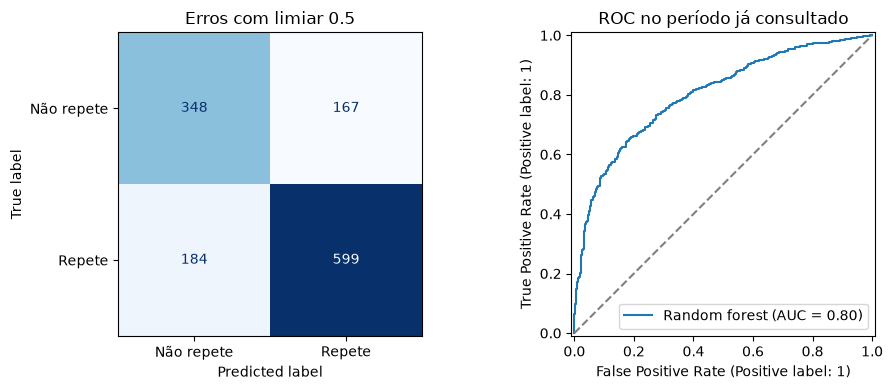

,compras,probabilidade_media,taxa_real
intervalo,,,
"(-0.001, 0.2]",29,0.1819,0.1379
"(0.2, 0.4]",321,0.3092,0.3209
"(0.4, 0.6]",385,0.5049,0.5013
"(0.6, 0.8]",365,0.6963,0.8137
"(0.8, 1.0]",198,0.8956,0.9394


In [50]:
confusion = confusion_matrix(y_val, val_predictions, labels=[0, 1])
tn, fp, fn, tp = confusion.ravel()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
ConfusionMatrixDisplay(confusion, display_labels=["Não repete", "Repete"]).plot(
    ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Erros com limiar 0.5")
RocCurveDisplay.from_predictions(y_val, val_probabilities, ax=axes[1],
                                name=chosen_model_name)
axes[1].plot([0, 1], [0, 1], "--", color="grey")
axes[1].set_title("ROC no período já consultado")
fig.tight_layout()
plt.show()

diagnostic = pd.DataFrame({
    "ID": train_clean.loc[X_val.index, "ID"], "data": dates.loc[X_val.index],
    "alvo": y_val, "probabilidade": val_probabilities, "previsão": val_predictions,
})
diagnostic["intervalo"] = pd.cut(diagnostic["probabilidade"],
                                 bins=np.linspace(0, 1, 6), include_lowest=True)
probability_groups = diagnostic.groupby("intervalo", observed=True).agg(
    compras=("alvo", "size"), probabilidade_media=("probabilidade", "mean"),
    taxa_real=("alvo", "mean"))
display(probability_groups.round(4))

## 8. Guardar a receita para o NB_5

Guardamos apenas `output/modelling/receita_escolhida.json`, o ficheiro que o NB_5 utiliza para recuperar o algoritmo, a seleção de variáveis e os parâmetros escolhidos (essencialmente tudo o que foi feito neste notebook). 

O JSON inclui outras informações como as versões das bibliotecas. Executar novamente substitui o ficheiro; não exporta as tabelas, previsões, avisos ou listas de colunas para ficheiros separados. Esses resultados continuam disponíveis nas saídas das secções anteriores deste notebook.



In [51]:
import json
from datetime import datetime, timezone

OUTPUT = ROOT / "output" / "modelling"
OUTPUT.mkdir(parents=True, exist_ok=True)
recipe = {
    "criado_utc": datetime.now(timezone.utc).isoformat(),
    "candidato": chosen_id, **chosen_spec,
    "parametros_completos_classificador": chosen_pipeline.named_steps["model"].get_params(),
    "selecao_L1_C": 0.1 if chosen_spec["seleção"] == "L1 C=0.1" else None,
    "preparacao": {"numericas": "mediana + indicador + StandardScaler",
                   "categoricas": "__missing__ + one-hot", "min_frequency": 20,
                   "constantes": "VarianceThreshold", "matriz": "densa",
                   "include_clientes": False, "include_random_noise": False,
                   "logaritmos": False},
    "features_originais": X.columns.tolist(),
    "limiar_diagnostico": THRESHOLD, "semente": RANDOM_STATE,
    "metrica_escolha": "ROC-AUC média não ponderada das 3 divisões internas",
    "auc_interna": float(chosen_row["media_auc"]),
    "auc_Xval": float(holdout.loc["Escolhida", "ROC-AUC"]),
    "Xval_independente": False,
    "nota_avaliacao": "X_val já consultado no NB_3; períodos internos reutilizados na procura.",
    "margem_dias": 90, "inicio_Xval": str(boundary.date()),
    "versoes": {"python": platform.python_version(), "sklearn": sklearn.__version__,
                "pandas": pd.__version__, "numpy": np.__version__},
    "refazer_ajuste_com_todo_treino_no_NB5": True,
}
(OUTPUT / "receita_escolhida.json").write_text(
    json.dumps(recipe, ensure_ascii=False, indent=2, allow_nan=False), encoding="utf-8")
print("Receita guardada em:", OUTPUT / "receita_escolhida.json")

Receita guardada em: c:\Users\leoms\Universidade\Mestrado\Machine Learning\Prática\ML_Project_G17\output\modelling\receita_escolhida.json


### Continuação do trabalho

No [Notebook 5 — Ajuste final e previsões para o Kaggle](NB_5_deployment.ipynb), recuperamos a receita escolhida, ajustamos o processo com todas as compras de treino utilizáveis e geramos as previsões para o conjunto de teste.
